# Redundancy in the measured multi-section data (Section 4.2.4, SI Section 6.11, Fig. S10)

Pairs of configurations of the multi-section dataset whose tip poses differ by less than $5$ mm and $5^\circ$ but whose tendon vectors differ markedly,
i.e. measured motion in the null space of the pose task.
(a) For each pair: distance between the two tip positions and between the two tendon vectors (boxes: median and interquartile range; whiskers: full range).
(b) Tendon displacements of the two configurations A and B of the example pair, the one with the largest tendon difference among the pairs in which no tendon
is released beyond its preload ($\delta\ell \le 0$ for all nine tendons); A is the configuration closer to mid-range, with
$H(l) = \frac{1}{2}\|l - \bar l\|^2$ and $\bar l$ the mean tendon vector stored in `models/kinematics/DELTAL_stats.pt` (secondary objective of Section 3.3.2).

**Inputs** (repository): `data/FKdata.pt` ($10{,}000$ measured configurations: tendon vector `DELTAL` [mm] and tip-III pose `tip3_pose`, position [mm] and ZYX Euler angles [rad]),
`models/kinematics/DELTAL_stats.pt`.
**Output**: `results/figS10_redundancy_pairs.pdf` and the numbers quoted in Section 4.2.4 and in the caption of Fig. S10. Run from inside `MULTI/`.

In [1]:
import shutil
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.spatial.transform import Rotation as R

plt.rcParams.update({
    "font.family": "serif", "font.size": 13, "axes.labelsize": 14, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "gray", "grid.linewidth": 0.5, "grid.alpha": 0.3,
    "text.usetex": shutil.which("latex") is not None, "mathtext.fontset": "cm",
})

POS_TOL, ROT_TOL = 5.0, 5.0   # [mm], [deg]

data = torch.load("data/FKdata.pt", map_location="cpu")
L = torch.stack(list(data["DELTAL"])).double().numpy()        # (10000, 9) tendon displacements [mm]
P = torch.stack(list(data["tip3_pose"])).double().numpy()     # (10000, 6) tip pose [mm, rad]
l_bar = torch.load("models/kinematics/DELTAL_stats.pt")["mean"].double().numpy()


def H(l):
    """Secondary objective: half squared distance of the tendon vector from mid-range."""
    return 0.5 * np.sum((l - l_bar) ** 2, axis=-1)

## Pairs with the same tip pose

In [2]:
cand = np.array(sorted(cKDTree(P[:, :3]).query_pairs(POS_TOL)))               # tip positions closer than 5 mm
rot = np.degrees((R.from_euler("zyx", P[cand[:, 1], 3:]) * R.from_euler("zyx", P[cand[:, 0], 3:]).inv()).magnitude())
pairs, rot = cand[rot < ROT_TOL], rot[rot < ROT_TOL]                           # and orientations closer than 5 deg
d_pos = np.linalg.norm(P[pairs[:, 0], :3] - P[pairs[:, 1], :3], axis=1)
d_ten = np.linalg.norm(L[pairs[:, 0]] - L[pairs[:, 1]], axis=1)
preload = np.all(L[pairs[:, 0]] <= 0, axis=1) & np.all(L[pairs[:, 1]] <= 0, axis=1)   # no tendon released beyond its preload

print(f"{len(pairs)} pairs within {POS_TOL:.0f} mm and {ROT_TOL:.0f} deg")
print(f"tip position difference: median {np.median(d_pos):.2f} mm, max {d_pos.max():.2f} mm")
print(f"tendon vector difference: median {np.median(d_ten):.1f} mm (range {d_ten.min():.1f} to {d_ten.max():.1f} mm)")
print(f"{preload.sum()} pairs with no tendon released beyond its preload: median tendon difference {np.median(d_ten[preload]):.1f} mm")

# Example pair: largest tendon difference among the preload-respecting pairs; A is the configuration closer to mid-range
k = np.flatnonzero(preload)[np.argmax(d_ten[preload])]
a, b = pairs[k] if H(L[pairs[k, 0]]) <= H(L[pairs[k, 1]]) else pairs[k][::-1]
print(f"\nExample pair (dataset indices A = {a}, B = {b}): tip poses {d_pos[k]:.1f} mm and {rot[k]:.1f} deg apart, "
      f"tendon vectors {d_ten[k]:.1f} mm apart, H(l) {H(L[a]):.0f} (A) against {H(L[b]):.0f} mm^2 (B)")
print("A:", np.round(L[a], 1)); print("B:", np.round(L[b], 1))

339 pairs within 5 mm and 5 deg
tip position difference: median 3.83 mm, max 5.00 mm
tendon vector difference: median 21.2 mm (range 1.9 to 64.2 mm)
85 pairs with no tendon released beyond its preload: median tendon difference 17.8 mm

Example pair (dataset indices A = 1783, B = 5931): tip poses 4.6 mm and 4.7 deg apart, tendon vectors 41.5 mm apart, H(l) 391 (A) against 655 mm^2 (B)
A: [ -4.6 -20.7 -30.4 -25.2  -1.7  -6.4 -12.2 -17.1 -11.8]
B: [ -6.2 -13.7 -20.8 -19.9 -27.4 -25.2 -23.4  -6.  -28.8]


## Fig. S10

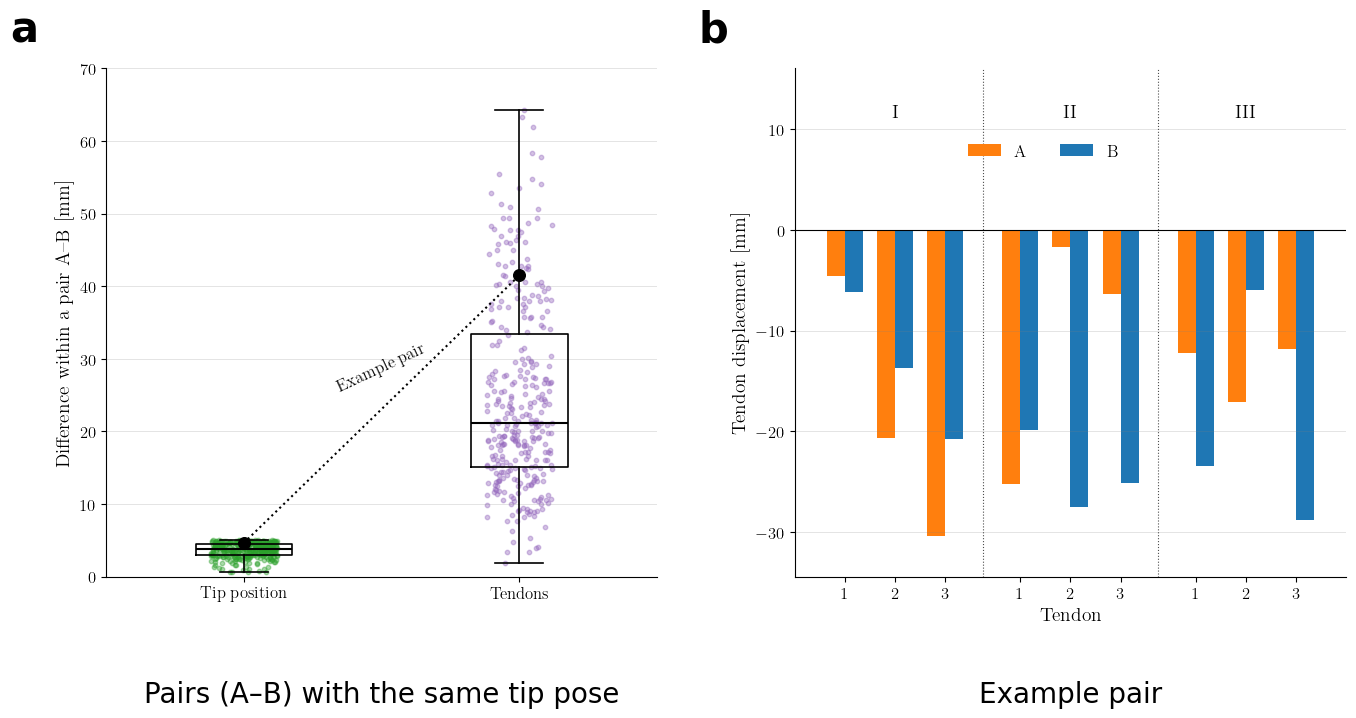

Saved results/figS10_redundancy_pairs.pdf


In [3]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(16, 6.6), gridspec_kw={"wspace": 0.25})
rng = np.random.default_rng(0)

# (a) differences within each pair
ax_a.boxplot([d_pos, d_ten], positions=[1, 2], widths=0.35, whis=(0, 100), showfliers=False,
             medianprops={"color": "k", "lw": 1.5}, boxprops={"lw": 1.2}, whiskerprops={"lw": 1.2}, capprops={"lw": 1.2})
for x, v, c in [(1, d_pos, "tab:green"), (2, d_ten, "tab:purple")]:
    ax_a.scatter(x + rng.uniform(-0.12, 0.12, len(v)), v, s=10, color=c, alpha=0.4, zorder=1)
ax_a.plot([1, 2], [d_pos[k], d_ten[k]], ":", color="k", lw=1.5)
ax_a.scatter([1, 2], [d_pos[k], d_ten[k]], s=70, color="k", zorder=3)
ax_a.text(1.5, 0.5 * (d_pos[k] + d_ten[k]) + 2, "Example pair", rotation=np.degrees(np.arctan2(d_ten[k] - d_pos[k], 70)) * 0.9,
          ha="center", va="bottom", fontsize=12)
ax_a.set_xticks([1, 2], ["Tip position", "Tendons"])
ax_a.set_xlim(0.5, 2.5); ax_a.set_ylim(0, 70)
ax_a.set_ylabel("Difference within a pair A--B [mm]" if plt.rcParams["text.usetex"] else "Difference within a pair A–B [mm]")
ax_a.grid(axis="x", visible=False)

# (b) tendon displacements of the example pair
x = np.arange(9) + np.repeat([0, 0.5, 1.0], 3)
ax_b.bar(x - 0.18, L[a], width=0.36, color="tab:orange", label="A")
ax_b.bar(x + 0.18, L[b], width=0.36, color="tab:blue", label="B")
ax_b.axhline(0, color="k", lw=0.8)
for sep in (2.75, 6.25):
    ax_b.axvline(sep, color="0.3", lw=0.8, ls=":")
for xc, sec in zip((1, 4.5, 8), ("I", "II", "III")):
    ax_b.text(xc, 0.93, sec, transform=ax_b.get_xaxis_transform(), ha="center", va="top", fontsize=14)
ax_b.set_xticks(x, [str(i % 3 + 1) for i in range(9)])
ax_b.set_xlim(-1, 10.0); ax_b.set_ylim(min(L[a].min(), L[b].min()) - 4, 16)
ax_b.set_xlabel("Tendon"); ax_b.set_ylabel("Tendon displacement [mm]")
ax_b.legend(loc="upper center", bbox_to_anchor=(0.45, 0.88), ncol=2, frameon=False)
ax_b.grid(axis="x", visible=False)

for ax, letter, title in [(ax_a, "a", "Pairs (A–B) with the same tip pose"), (ax_b, "b", "Example pair")]:
    pos = ax.get_position()
    fig.text(pos.x0 - 0.06, 0.97, letter, fontsize=30, fontweight="bold", family="sans-serif", usetex=False, va="top")
    fig.text(0.5 * (pos.x0 + pos.x1), -0.08, title, fontsize=20, family="sans-serif", usetex=False, ha="center")
fig.savefig("results/figS10_redundancy_pairs.pdf", bbox_inches="tight")
plt.show()
print("Saved results/figS10_redundancy_pairs.pdf")